# UMUD — prediction only (uses saved weights)

Runs the trained aponeurosis and fascicle models on the test images and writes `submission.csv`.
**No training** — takes a few minutes.

**Before running**
1. Attach the competition data (right panel → *Add Input* → *Competitions*).
2. Attach the output of your training notebook that contains `apo_f0_unet.pt` and `fasc_f0_unet.pt`
   (*Add Input* → *Your Work*). The weights are found automatically.
3. GPU is faster, CPU also works.

**After running:** download `/kaggle/working/submission.csv` from the *Output* panel and upload it via
*Submit Prediction*. Also check the printed calibration table (`depth_mm` vs. the depth on the scanner screen).

In [1]:
import os, re, json, math, time, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

CFG = dict(
    INPUT_ROOT="/kaggle/input",
    WORK_DIR="/kaggle/working",
    SEED=42,
    IMG_SIZE=512,           # network input (square)
    VAL_FRAC=0.15,
    BATCH=8,
    LR=3e-4,
    WD=1e-4,
    APO_EPOCHS=40,
    FASC_EPOCHS=30,
    NUM_WORKERS=2,
    TRAIN=False,            # this notebook never trains
    WEIGHTS_DIR=None,       # None -> search /kaggle/input for *_unet.pt automatically
    PRETRAINED=True,        # ImageNet encoder (needs internet once; falls back to random init)
    FASC_DILATE=3,          # thicken thin fascicle labels for training
    TTA=True,               # horizontal-flip test-time augmentation
    APO_THR=0.5,
    FASC_THR=0.35,
    APO_RETRY_THR=(0.35, 0.2),   # second/third attempt when no aponeurosis pair is found
    FASC_RETRY_THR=(0.2, 0.1),   # second/third attempt when no fascicle segments are found
    N_FOLDS=1,              # >1 -> group k-fold models, probabilities averaged (reproducible ensemble)
    MT_EDGE="inner",        # "inner": inner aponeurosis borders (manual protocol); "center": band centre lines
    PA_SHRINK_K=2.0,        # low-confidence PA is shrunk toward the group median: w = n_segs/(n_segs+K)
    LOCAL_LABELS=None,      # optional CSV (image_id, pa_deg, fl_mm, mt_mm) of your own annotations to score against
    MIN_FASC_LEN_FRAC=0.04, # min fascicle-segment length as fraction of FOV width
    PA_RANGE=(5.0, 45.0),
    FL_RANGE=(30.0, 200.0),
    MT_RANGE=(10.0, 50.0),
    # calibration
    TICK_MM_CANDIDATES=(2.0, 2.5, 5.0, 10.0),  # possible mm per tick interval
    TICK_MM_PENALTY={2.0: 0.3, 2.5: 0.3},      # 5 mm / 10 mm rulers are the usual ones
    H_TICK_MM={10.0: 0.0, 5.0: 1.0},  # bottom-edge rulers: every Telemed one seen uses 10 mm (penalty for 5 mm)
    DEPTH_RANGE_MM=(20.0, 90.0),  # plausible scan depth for these muscles
    DEPTH_PRIOR_MM=45.0,    # typical depth, only used to choose between tick units
    MT_PRIOR_MM=20.0,       # typical MT, only used to choose between tick units
    DEFAULT_DEPTH_MM=40.0,  # used only when no valid ruler exists anywhere
    CALIB_MM_PER_TICK={},   # manual override per image size, e.g. {"1551x813": 5.0}
    CALIB_PX_PER_MM={},     # manual override per image size, e.g. {"1024x768": 12.3}
    # temporal smoothing
    SEQ_SIM_THR=0.93,
    SEQ_MAX_NEIGHBORS=4,
    DEBUG_MAX_TRAIN=None,   # int -> subsample training sets for a quick dry run
    ROW_REJECT_MT_FRAC=0.9, # MT below 0.9 x MT_RANGE min (9 mm) -> wrong structures, reject the image's values
    ROW_REJECT_PA_DEG=4.0,  # PA below this (test range starts at 5 deg) -> reject the image's values
    PREFER_TOP_PAIR=False,  # True -> measure the most superficial muscle (VL / GM / RF are all the top muscle)
    ASPECT_CORRECT=False,   # True -> correct PA/FL for non-square pixels (stretched screenshots); test both
    CONST_TARGETS=[],       # diagnostic only: e.g. ["fl_mm"] -> that column becomes its median (find the weakest target)
    SUB_SEP=",",            # submission separator (the official sample uses ";" — switch only if Kaggle rejects ",")
)
# optional JSON overrides (handy for quick experiments / CI)
if os.environ.get("UMUD_CFG"):
    CFG.update(json.loads(os.environ["UMUD_CFG"]))

random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"])
WORK = Path(CFG["WORK_DIR"]); WORK.mkdir(parents=True, exist_ok=True)
WEIGHTS = Path(CFG["WEIGHTS_DIR"]) if CFG["WEIGHTS_DIR"] else WORK
print(json.dumps({k: v for k, v in CFG.items() if not isinstance(v, dict)}, indent=1))

{
 "INPUT_ROOT": "/kaggle/input",
 "WORK_DIR": "/kaggle/working",
 "SEED": 42,
 "IMG_SIZE": 512,
 "VAL_FRAC": 0.15,
 "BATCH": 8,
 "LR": 0.0003,
 "WD": 0.0001,
 "APO_EPOCHS": 40,
 "FASC_EPOCHS": 30,
 "NUM_WORKERS": 2,
 "TRAIN": false,
 "WEIGHTS_DIR": null,
 "PRETRAINED": true,
 "FASC_DILATE": 3,
 "TTA": true,
 "APO_THR": 0.5,
 "FASC_THR": 0.35,
 "APO_RETRY_THR": [
  0.35,
  0.2
 ],
 "FASC_RETRY_THR": [
  0.2,
  0.1
 ],
 "N_FOLDS": 1,
 "MT_EDGE": "inner",
 "PA_SHRINK_K": 2.0,
 "LOCAL_LABELS": null,
 "MIN_FASC_LEN_FRAC": 0.04,
 "PA_RANGE": [
  5.0,
  45.0
 ],
 "FL_RANGE": [
  30.0,
  200.0
 ],
 "MT_RANGE": [
  10.0,
  50.0
 ],
 "TICK_MM_CANDIDATES": [
  2.0,
  2.5,
  5.0,
  10.0
 ],
 "DEPTH_RANGE_MM": [
  20.0,
  90.0
 ],
 "DEPTH_PRIOR_MM": 45.0,
 "MT_PRIOR_MM": 20.0,
 "DEFAULT_DEPTH_MM": 40.0,
 "SEQ_SIM_THR": 0.93,
 "SEQ_MAX_NEIGHBORS": 4,
 "DEBUG_MAX_TRAIN": null,
 "ROW_REJECT_MT_FRAC": 0.9,
 "ROW_REJECT_PA_DEG": 4.0,
 "PREFER_TOP_PAIR": false,
 "ASPECT_CORRECT": false,
 "CONST_TARGETS"

## 1. I/O helpers and test data

In [2]:
IMG_EXT = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

def list_images(d):
    return sorted(p for p in Path(d).rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXT)

def find_dirs(root):
    """Locate the competition folders regardless of version suffixes (_v1, _v2 ...)."""
    pats = [("apo_img", r"^apo_im"), ("apo_mask", r"^apo_mask"),
            ("fasc_img", r"^fasc_im"), ("fasc_mask", r"^fasc_mask"), ("test", r"^test")]
    hits = {}
    for d in sorted(Path(root).rglob("*")):
        if not d.is_dir():
            continue
        n = d.name.lower()
        for key, pat in pats:
            if key not in hits and re.match(pat, n):
                hits[key] = d
    return hits

def find_sample_submission(root, test_dir=None):
    """The sample_submission.csv closest to the test images (other attached inputs may contain copies)."""
    cands = sorted(Path(root).rglob("sample_submission.csv"))
    if not cands:
        return None
    if test_dir is None:
        return cands[0]
    t = Path(test_dir).parts
    common = lambda c: sum(1 for a, b in zip(c.parts, t) if a == b)
    return max(cands, key=common)

def read_gray(p):
    im = cv2.imread(str(p), cv2.IMREAD_UNCHANGED)
    if im is None:
        from PIL import Image
        im = np.array(Image.open(p))
        if im.ndim == 3:
            im = im[..., ::-1]  # RGB -> BGR
    if im.ndim == 3:
        im = im[..., :3]
        im = cv2.cvtColor(np.ascontiguousarray(im), cv2.COLOR_BGR2GRAY)
    if im.dtype != np.uint8:
        im = im.astype(np.float32)
        im = (255 * (im - im.min()) / max(float(im.max() - im.min()), 1e-6)).astype(np.uint8)
    return im

def read_mask(p):
    m = read_gray(p)
    mx = m.max()
    return (m > (mx / 2.0 if mx > 0 else 1)).astype(np.uint8)

def norm_stem(p):
    s = Path(p).stem.lower()
    s = re.sub(r"[_\-\s]?(mask|label|seg|gt)s?$", "", s)
    s = re.sub(r"^(mask|label)s?[_\-\s]?", "", s)
    return s

def pair_images_masks(img_dir, mask_dir):
    imgs, masks = list_images(img_dir), list_images(mask_dir)
    mm = {}
    for m in masks:
        mm.setdefault(norm_stem(m), m)
    pairs = [(i, mm[norm_stem(i)]) for i in imgs if norm_stem(i) in mm]
    if len(pairs) < 0.5 * len(imgs) and len(imgs) == len(masks):
        warnings.warn("Name matching failed; pairing images and masks by sorted order.")
        pairs = list(zip(imgs, masks))
    print(f"{Path(img_dir).name}: {len(imgs)} images, {len(masks)} masks, {len(pairs)} pairs")
    return pairs

import hashlib

def sha256_file(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for b in iter(lambda: fh.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

def drop_exact_duplicates(pairs, name):
    """Keep one record per byte-identical (image, mask) pair. Also reports images that appear
    with *different* masks (conflicting labels are kept; they act as label-noise averaging)."""
    seen, kept, dups, img_masks = {}, [], [], {}
    for ip, mp in pairs:
        hi, hm = sha256_file(ip), sha256_file(mp)
        img_masks.setdefault(hi, set()).add(hm)
        if (hi, hm) in seen:
            dups.append((Path(ip).name, Path(seen[(hi, hm)]).name))
        else:
            seen[(hi, hm)] = ip; kept.append((ip, mp))
    conflicts = sum(len(v) > 1 for v in img_masks.values())
    print(f"{name}: {len(pairs)} pairs -> {len(kept)} unique "
          f"({len(dups)} exact duplicates removed, {conflicts} images with conflicting masks)")
    if dups:
        print("   e.g.", dups[:3])
    return kept, pd.DataFrame(dups, columns=["removed", "duplicate_of"])

In [3]:
# test images + sample submission only (no training data needed)
assert Path(CFG["INPUT_ROOT"]).exists(), f"{CFG['INPUT_ROOT']} not found"
DIRS = find_dirs(CFG["INPUT_ROOT"])
assert "test" in DIRS, "test image folder not found — is the competition data attached?"
SAMPLE_SUB = find_sample_submission(CFG["INPUT_ROOT"], DIRS["test"])
TEST_FILES = list_images(DIRS["test"])
print("test folder:", DIRS["test"], "| images:", len(TEST_FILES), "| sample:", SAMPLE_SUB)

test folder: /kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/test_images_v2 | images: 309 | sample: /kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/sample_submission.csv


## 2. Field-of-view crop

In [4]:
def _longest_run(b):
    """(start, end_exclusive) of the longest True run in a 1-D bool array."""
    best, cur, start, bs = 0, 0, 0, 0
    for i, v in enumerate(b):
        if v:
            if cur == 0:
                start = i
            cur += 1
            if cur > best:
                best, bs = cur, start
        else:
            cur = 0
    return (bs, bs + best) if best > 0 else (0, len(b))

def _fill_gaps(b, max_gap):
    """Turn short False runs that lie between True values into True (bridges dark bands in an image)."""
    b = b.copy(); idx = np.nonzero(b)[0]
    if len(idx) < 2:
        return b
    for a, c in zip(idx[:-1], idx[1:]):
        if 1 < c - a <= max_gap + 1:
            b[a:c] = True
    return b

def fov_box(g):
    """Bounding box (x, y, w, h) of the B-mode image area inside a screenshot.
    Uses local texture (speckle) and row/column projections so side text and colour bars are ignored.
    Thresholds are low and short gaps are bridged, so dark muscle regions (low gain, sparse fascicles)
    stay inside the box; uniform UI panels (black or grey) have no texture and stay outside."""
    H, W = g.shape
    f = g.astype(np.float32)
    mu = cv2.blur(f, (15, 15))
    # texture = left-right intensity changes: speckle has them, UI border lines / bars do not
    gx = cv2.blur(np.abs(cv2.Sobel(f, cv2.CV_32F, 1, 0, ksize=3)), (15, 15))
    m = ((gx > 6) & (mu > 3)).astype(np.uint8) * 255
    m = cv2.medianBlur(m, 5) > 0
    r0, r1 = _longest_run(_fill_gaps(m.mean(1) > 0.2, int(0.2 * H)))
    c0, c1 = _longest_run(_fill_gaps(m[r0:r1].mean(0) > 0.5, int(0.03 * W)))
    r0, r1 = _longest_run(_fill_gaps(m[:, c0:c1].mean(1) > 0.3, int(0.2 * H)))
    c0, c1 = _longest_run(_fill_gaps(m[r0:r1].mean(0) > 0.5, int(0.03 * W)))
    w, h = c1 - c0, r1 - r0
    if w * h < 0.15 * H * W or w * h > 0.92 * H * W or w < 32 or h < 32:
        return (0, 0, W, H)
    e = 7  # the 15x15 texture window bleeds ~7 px past the true border
    return (int(c0 + e), int(r0 + e), int(w - 2 * e), int(h - 2 * e))

def crop(a, box):
    x, y, w, h = box
    return a[y:y + h, x:x + w]

def dhash(g, n=8):
    s = cv2.resize(g, (n + 1, n), interpolation=cv2.INTER_AREA).astype(np.int16)
    bits = (s[:, 1:] > s[:, :-1]).flatten()
    return np.packbits(bits).view(">u8")[0] if n == 8 else bits

def duplicate_groups(hashes, max_dist=5):
    """Union-find over perceptual hashes: exact and near duplicates share a group (keeps them out of val)."""
    h = np.asarray(hashes, dtype=np.uint64)
    n = len(h)
    parent = list(range(n))
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]; i = parent[i]
        return i
    pairs = []
    for s in range(0, n, 256):  # chunked to keep memory small
        x = (h[s:s + 256, None] ^ h[None, :]).view(np.uint8).reshape(-1, n, 8)
        dist = np.unpackbits(x, axis=2).sum(2)
        ii, jj = np.nonzero(dist <= max_dist)
        pairs += [(i + s, j) for i, j in zip(ii, jj) if i + s < j]
    for i, j in pairs:
        a, b = find(i), find(j)
        if a != b:
            parent[b] = a
    return np.array([find(i) for i in range(n)])

def load_pairs(pairs, size, thin=False):
    """Read, FOV-crop and resize image/mask pairs into memory."""
    X = np.zeros((len(pairs), size, size), np.uint8)
    Y = np.zeros((len(pairs), size, size), np.uint8)
    hashes = []
    for k, (ip, mp) in enumerate(pairs):
        g, m = read_gray(ip), read_mask(mp)
        if m.shape != g.shape:
            m = cv2.resize(m, g.shape[::-1], interpolation=cv2.INTER_NEAREST)
        b = fov_box(g)
        g, m = crop(g, b), crop(m, b)
        X[k] = cv2.resize(g, (size, size), interpolation=cv2.INTER_AREA)
        mf = cv2.resize(m.astype(np.float32), (size, size), interpolation=cv2.INTER_LINEAR if thin else cv2.INTER_NEAREST)
        Y[k] = (mf > (0.2 if thin else 0.5)).astype(np.uint8)
        hashes.append(dhash(X[k]))
    groups = duplicate_groups(hashes)
    print(f"loaded {len(pairs)} pairs, {len(set(groups))} unique groups "
          f"({len(pairs) - len(set(groups))} near/exact duplicates)")
    return X, Y, groups

def group_split(groups, val_frac, seed, n_folds=1, fold=0):
    """Train/val indices with whole duplicate groups on one side. n_folds>1 -> group k-fold, fold `fold`."""
    ug = np.unique(groups)
    rng = np.random.default_rng(seed); rng.shuffle(ug)
    if n_folds > 1:
        val_g = set(np.array_split(ug, n_folds)[fold])
    else:
        val_g = set(ug[: max(1, int(round(val_frac * len(ug))))])
    va = np.array([g in val_g for g in groups])
    return np.nonzero(~va)[0], np.nonzero(va)[0]

## 3. Load the trained models

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(CFG["SEED"])
print("device:", DEVICE)

class ConvBlock(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class Up(nn.Module):
    def __init__(self, cin, cskip, cout):
        super().__init__()
        self.conv = ConvBlock(cin + cskip, cout)
    def forward(self, x, skip=None):
        size = skip.shape[-2:] if skip is not None else (x.shape[-2] * 2, x.shape[-1] * 2)
        x = F.interpolate(x, size=size, mode="bilinear", align_corners=False)
        if skip is not None:
            x = torch.cat([x, skip], 1)
        return self.conv(x)

class ResUNet(nn.Module):
    """U-Net with a torchvision ResNet-34 encoder; grayscale input in [0, 1]."""
    def __init__(self, pretrained=True):
        super().__init__()
        enc = None
        if pretrained:
            try:
                enc = torchvision.models.resnet34(weights=torchvision.models.ResNet34_Weights.IMAGENET1K_V1)
            except Exception as e:
                print("ImageNet weights unavailable, random init:", type(e).__name__)
        if enc is None:
            enc = torchvision.models.resnet34(weights=None)
        self.stem = nn.Sequential(enc.conv1, enc.bn1, enc.relu)
        self.pool = enc.maxpool
        self.l1, self.l2, self.l3, self.l4 = enc.layer1, enc.layer2, enc.layer3, enc.layer4
        self.u4, self.u3 = Up(512, 256, 256), Up(256, 128, 128)
        self.u2, self.u1, self.u0 = Up(128, 64, 64), Up(64, 64, 64), Up(64, 0, 32)
        self.head = nn.Conv2d(32, 1, 1)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x):
        x = (x.repeat(1, 3, 1, 1) - self.mean) / self.std
        x0 = self.stem(x)
        x1 = self.l1(self.pool(x0))
        x2 = self.l2(x1); x3 = self.l3(x2); x4 = self.l4(x3)
        d = self.u4(x4, x3); d = self.u3(d, x2); d = self.u2(d, x1); d = self.u1(d, x0); d = self.u0(d)
        return self.head(d)

device: cuda


In [6]:
S = CFG["IMG_SIZE"]   # must match the size the models were trained with (512)

def find_weights(name):
    """All fold weights for `name` (e.g. apo_f0_unet.pt), from WEIGHTS_DIR or anywhere under /kaggle/input."""
    roots = [Path(CFG["WEIGHTS_DIR"])] if CFG["WEIGHTS_DIR"] else [Path(CFG["INPUT_ROOT"]), WORK]
    hits = []
    for r in roots:
        if r.exists():
            hits += sorted(r.rglob(f"{name}_f*_unet.pt"))
    if not hits:
        raise FileNotFoundError(
            f"No {name}_f*_unet.pt found. Add the output of your training notebook as an input "
            f"(right panel -> Add Input -> Your Work) or set CFG['WEIGHTS_DIR'].")
    folder = hits[0].parent           # use one folder so folds from different runs don't mix
    return sorted(p for p in hits if p.parent == folder)

def load_models(name):
    models = []
    for p in find_weights(name):
        m = ResUNet(pretrained=False).to(DEVICE)
        m.load_state_dict(torch.load(p, map_location=DEVICE))
        models.append(m.eval())
        print(f"loaded {p}")
    return models

APO_MODELS, FASC_MODELS = load_models("apo"), load_models("fasc")

loaded /kaggle/input/notebooks/trident3/muscle-v2/apo_f0_unet.pt
loaded /kaggle/input/notebooks/trident3/muscle-v2/fasc_f0_unet.pt


## 4. Geometry

In [7]:
def robust_line(xs, ys, iters=3):
    """y = a*x + b with iterative MAD outlier rejection."""
    xs, ys = np.asarray(xs, float), np.asarray(ys, float)
    a, b = np.polyfit(xs, ys, 1)
    for _ in range(iters):
        r = ys - (a * xs + b)
        s = 1.4826 * np.median(np.abs(r - np.median(r))) + 1e-6
        keep = np.abs(r) < 2.5 * s + 1.0
        if keep.sum() < 10:
            break
        a, b = np.polyfit(xs[keep], ys[keep], 1)
    return float(a), float(b)

def _border_points(mask, side):
    """Per-column inner border of a band: side='bottom' -> max row, 'top' -> min row."""
    cols = np.nonzero(mask.any(0))[0]
    if len(cols) == 0:
        return cols, cols
    if side == "bottom":
        ys = mask.shape[0] - 1 - np.argmax(mask[::-1, cols], axis=0)
    elif side == "center":
        sub = mask[:, cols].astype(np.float64)
        ys = (sub * np.arange(mask.shape[0])[:, None]).sum(0) / sub.sum(0)
    else:
        ys = np.argmax(mask[:, cols], axis=0)
    return cols, ys

def find_aponeuroses(apo_prob, fasc_prob=None, thr=0.5, edge="inner", min_width=0.08, min_cover=0.25):
    """Returns dict with superficial/deep inner-border lines (a, b) or None."""
    H, W = apo_prob.shape
    m = (apo_prob > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    comps = []
    for i in range(1, n):
        if st[i, cv2.CC_STAT_AREA] < 0.0005 * H * W or st[i, cv2.CC_STAT_WIDTH] < min_width * W:
            continue
        ys, xs = np.nonzero(lab == i)
        a, b = robust_line(xs, ys) if len(xs) >= 10 else (0.0, float(ys.mean()))
        comps.append(dict(ids=[i], a=a, b=b, xmin=xs.min(), xmax=xs.max()))
    # merge fragments of the same aponeurosis (close centre lines)
    comps.sort(key=lambda c: c["a"] * W / 2 + c["b"])
    merged = []
    for c in comps:
        if merged:
            p = merged[-1]
            xm = W / 2
            if abs((c["a"] * xm + c["b"]) - (p["a"] * xm + p["b"])) < 0.04 * H:
                p["ids"] += c["ids"]; p["xmin"] = min(p["xmin"], c["xmin"]); p["xmax"] = max(p["xmax"], c["xmax"])
                continue
        merged.append(dict(c))
    bands = []
    for c in merged:
        bm = np.isin(lab, c["ids"])
        cover = bm.any(0).mean()
        if cover < min_cover:
            continue
        bands.append(dict(mask=bm, cover=cover, yc=c["a"] * W / 2 + c["b"]))
    if len(bands) < 2:
        return None
    bands.sort(key=lambda d: d["yc"])
    # choose the adjacent pair that encloses the most fascicle signal (the muscle of interest)
    cands = []  # (score, pair) for adjacent band pairs, top to bottom
    for k in range(len(bands) - 1):
        top, bot = bands[k], bands[k + 1]
        if bot["yc"] - top["yc"] < 0.06 * H:
            continue
        s = 0.5 * min(top["cover"], bot["cover"])
        if fasc_prob is not None:
            y0, y1 = int(max(0, top["yc"])), int(min(H, bot["yc"]))
            s += float(fasc_prob[y0:y1].mean()) * 10 if y1 > y0 else 0
        cands.append((s, (top, bot)))
    if not cands:
        return None
    if CFG.get("PREFER_TOP_PAIR") and fasc_prob is not None:
        # the target muscle is the most superficial one: take the top pair unless it clearly holds
        # much less fascicle signal than the best pair
        smax = max(s for s, _ in cands)
        best = next(p for s, p in cands if s >= 0.5 * smax)
    else:
        best = max(cands, key=lambda t: t[0])[1]
    if edge == "center":
        xs, ys = _border_points(best[0]["mask"], "center"); xd, yd = _border_points(best[1]["mask"], "center")
    else:
        xs, ys = _border_points(best[0]["mask"], "bottom"); xd, yd = _border_points(best[1]["mask"], "top")
    sup, deep = robust_line(xs, ys), robust_line(xd, yd)
    return dict(sup=sup, deep=deep, sup_cover=best[0]["cover"], deep_cover=best[1]["cover"])

def fascicle_segments(fasc_prob, apo=None, thr=0.35, min_len=20, margin_frac=0.03):
    """Elongated components of the fascicle probability map (inside the muscle if apo given)."""
    H, W = fasc_prob.shape
    p = fasc_prob.copy()
    if apo is not None:
        X = np.arange(W)[None, :]; Yg = np.arange(H)[:, None]
        (a_s, b_s), (a_d, b_d) = apo["sup"], apo["deep"]
        mt = np.abs((a_d - a_s) * W / 2 + (b_d - b_s))
        mg = margin_frac * mt
        inside = (Yg > a_s * X + b_s + mg) & (Yg < a_d * X + b_d - mg)
        p[~inside] = 0
    m = (p > thr).astype(np.uint8)
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    segs = []
    for i in range(1, n):
        x0, y0, w, h, area = st[i]
        if area < 8:
            continue
        sub = lab[y0:y0 + h, x0:x0 + w] == i
        ys, xs = np.nonzero(sub)
        pts = np.stack([xs + x0, ys + y0], 1).astype(float)
        c = pts.mean(0); C = np.cov((pts - c).T) + 1e-6 * np.eye(2)
        ev, evec = np.linalg.eigh(C)
        d = evec[:, 1]
        if d[0] < 0:
            d = -d
        proj = (pts - c) @ d
        length = proj.max() - proj.min()
        elong = math.sqrt(ev[1] / max(ev[0], 1e-6))
        if length < min_len or elong < 3:
            continue
        wgt = length * float(fasc_prob[ys + y0, xs + x0].mean())
        segs.append(dict(cx=c[0], cy=c[1], dx=d[0], dy=d[1], length=length, w=wgt))
    return segs

def structure_tensor_angle(img, region, sigma=6.0):
    """Dominant line orientation (radians, image coords, in (-pi/2, pi/2]) in a region."""
    f = img.astype(np.float32)
    gx = cv2.Sobel(f, cv2.CV_32F, 1, 0, ksize=5); gy = cv2.Sobel(f, cv2.CV_32F, 0, 1, ksize=5)
    jxx = cv2.GaussianBlur(gx * gx, (0, 0), sigma); jyy = cv2.GaussianBlur(gy * gy, (0, 0), sigma)
    jxy = cv2.GaussianBlur(gx * gy, (0, 0), sigma)
    coh = np.sqrt((jxx - jyy) ** 2 + 4 * jxy ** 2) / (jxx + jyy + 1e-6)
    w = coh * region
    # gradient orientation (doubled angle), averaged, then rotated 90deg -> line orientation
    c2 = (w * (jxx - jyy)).sum(); s2 = (w * 2 * jxy).sum()
    theta_g = 0.5 * math.atan2(s2, c2)
    return theta_g + math.pi / 2

def weighted_median(v, w):
    v, w = np.asarray(v, float), np.asarray(w, float)
    o = np.argsort(v); v, w = v[o], w[o]
    cw = np.cumsum(w)
    return float(v[np.searchsorted(cw, 0.5 * cw[-1])])

def signed_angle_to(u, f):
    """Signed angle (deg) from direction u to direction f (image coordinates)."""
    return math.degrees(math.atan2(u[0] * f[1] - u[1] * f[0], u[0] * f[0] + u[1] * f[1]))

def dominant_angle(segs, u):
    """Weighted-median signed angle (deg) of segments relative to direction u, using only the
    dominant fascicle orientation. Returns (angle or nan, n_used)."""
    ang, wts = [], []
    for s in segs:
        f = np.array([s["dx"], s["dy"]])
        if f @ u < 0:
            f = -f
        ang.append(signed_angle_to(u, f)); wts.append(s["w"])
    ang, wts = np.array(ang), np.array(wts)
    if len(ang) < 2:
        return np.nan, 0
    sign = 1.0 if wts[ang > 0].sum() >= wts[ang < 0].sum() else -1.0
    keep = (np.sign(ang) == sign) & (np.abs(ang) > 2) & (np.abs(ang) < 70)
    if keep.sum() < 2:
        return np.nan, 0
    return sign * weighted_median(np.abs(ang[keep]), wts[keep]), int(keep.sum())

def architecture_px(img, apo_prob, fasc_prob, cfg=CFG):
    """PA (deg), FL (px), MT (px) for one FOV crop + diagnostics."""
    H, W = img.shape
    out = dict(pa=np.nan, fl_px=np.nan, mt_px=np.nan, n_segs=0, method="fail", apo=None, segs=[], fl_lines=[])
    apo = find_aponeuroses(apo_prob, fasc_prob, cfg["APO_THR"], cfg["MT_EDGE"])
    retry = ""
    if apo is None:  # rescue: the model is often right but under-confident on unseen scanners
        for t in cfg["APO_RETRY_THR"]:
            apo = find_aponeuroses(apo_prob, fasc_prob, t, cfg["MT_EDGE"], min_width=0.05, min_cover=0.15)
            if apo is not None:
                retry = "_apo_retry"
                break
    if apo is None:
        return out
    out["apo"] = apo
    (a_s, b_s), (a_d, b_d) = apo["sup"], apo["deep"]
    xs_anchor = np.array([0.25, 0.5, 0.75]) * W
    # --- MT: perpendicular distance, both directions averaged, at 3 positions
    mts = []
    for x in xs_anchor:
        yd = a_d * x + b_d; ys_ = a_s * x + b_s
        d1 = abs(a_s * x - yd + b_s) / math.hypot(a_s, 1)
        d2 = abs(a_d * x - ys_ + b_d) / math.hypot(a_d, 1)
        mts.append(0.5 * (d1 + d2))
    out["mt_px"] = float(np.mean(mts))
    # --- PA: fascicle segments relative to the deep aponeurosis
    u = np.array([1.0, a_d]) / math.hypot(1.0, a_d)
    segs = fascicle_segments(fasc_prob, apo, cfg["FASC_THR"], max(10, cfg["MIN_FASC_LEN_FRAC"] * W))
    sa, n_used = dominant_angle(segs, u)
    method = "segments"
    if not np.isfinite(sa):  # rescue: weaker fascicle evidence before falling back to the structure tensor
        for t in cfg["FASC_RETRY_THR"]:
            segs = fascicle_segments(fasc_prob, apo, t, max(10, 0.75 * cfg["MIN_FASC_LEN_FRAC"] * W))
            sa, n_used = dominant_angle(segs, u)
            if np.isfinite(sa):
                method = "segments_retry"
                break
    out["segs"] = segs
    if np.isfinite(sa):
        out["n_segs"] = n_used; out["method"] = method + retry
    if np.isnan(sa):  # fallback: structure tensor inside the muscle
        X = np.arange(W)[None, :]; Yg = np.arange(H)[:, None]
        mg = 0.15 * out["mt_px"]  # stay clear of the bright aponeurosis edges
        region = ((Yg > a_s * X + b_s + mg) & (Yg < a_d * X + b_d - mg)).astype(np.float32)
        region *= (0.2 + fasc_prob)
        if region.sum() > 100:
            th = structure_tensor_angle(img, region, sigma=3.0)
            f = np.array([math.cos(th), math.sin(th)])
            if f @ u < 0:
                f = -f
            sa = signed_angle_to(u, f)
            out["method"] = "structure_tensor" + retry
    if np.isnan(sa) or abs(sa) < 1:
        return out
    out["pa"] = abs(sa)
    # --- FL: from deep anchors along the fascicle direction to the superficial line
    r = math.radians(sa)
    f = np.array([u[0] * math.cos(r) - u[1] * math.sin(r), u[0] * math.sin(r) + u[1] * math.cos(r)])
    if f[1] > 0:  # walk upwards (towards the superficial aponeurosis)
        f = -f
    fls = []
    for x in xs_anchor:
        q = np.array([x, a_d * x + b_d])
        den = f[1] - a_s * f[0]
        if abs(den) < 1e-9:
            continue
        t = (a_s * q[0] + b_s - q[1]) / den
        if t > 0:
            fls.append(t); out["fl_lines"].append((q, q + t * f))
    if fls:
        out["fl_px"] = float(np.mean(fls))
    return out

## 5. Calibration

In [8]:
def detect_ticks(g, box):
    """Find a column of regularly spaced short marks (depth ruler) outside the FOV interior.
    Returns dict(spacing_px, n, x) or None."""
    H, W = g.shape
    x, y, w, h = box
    bright = (g > 90).astype(np.uint8)
    pad = 6
    if w < W or h < H:
        bright[y + pad:y + h - pad, x + pad:x + w - pad] = 0
    # remove long straight lines (ruler spine, image frame) so the ticks attached to them become separate marks
    vert = cv2.morphologyEx(bright, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (1, 25)))
    horiz = cv2.morphologyEx(bright, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (45, 1)))
    bright = bright & (1 - vert) & (1 - horiz)
    n, lab, st, cen = cv2.connectedComponentsWithStats(bright, connectivity=8)
    cand = []
    for i in range(1, n):
        cx, cy, cw, ch, a = st[i]
        if 2 <= cw <= 40 and 1 <= ch <= 6 and a >= 2 and cw >= 0.6 * ch:
            cand.append((cx, cx + cw, cen[i][0], cen[i][1]))
    if len(cand) < 5:
        return None
    cand = np.array(cand)
    best = None
    for key in (0, 1, 2):  # align by left edge, right edge, centre
        o = np.argsort(cand[:, key]); c = cand[o]
        splits = np.nonzero(np.diff(c[:, key]) > 3)[0] + 1
        for grp in np.split(c, splits):
            if len(grp) < 5:
                continue
            ys = np.sort(grp[:, 3])
            ys = ys[np.concatenate([[True], np.diff(ys) > 3])]
            if len(ys) < 5:
                continue
            d = np.diff(ys); dm = np.median(d)
            if dm < max(12, 0.02 * h):          # rulers mark >= ~2 mm; denser patterns are text/dots
                continue
            k = np.round((ys - ys[0]) / dm)  # tolerate a few missing ticks
            res = ys - ys[0] - k * dm
            inl = np.abs(res) < 0.12 * dm
            if inl.sum() < 5:
                continue
            A = np.stack([k[inl], np.ones(inl.sum())], 1)
            sp = float(np.linalg.lstsq(A, ys[inl], rcond=None)[0][0])
            slots = k[inl].max() - k[inl].min() + 1
            fill = inl.sum() / slots              # fraction of expected tick positions that have a tick
            cover = (slots - 1) * sp / max(h, 1)  # fraction of the image height the ruler spans
            ov = max(0, min(ys[inl].max(), y + h) - max(ys[inl].min(), y)) / max(h, 1)
            # a depth ruler runs down most of the image with (almost) every tick present
            if fill < 0.7 or cover < 0.5 or ov < 0.4:
                continue
            score = inl.sum() * fill + 10 * cover
            if best is None or score > best["score"]:
                best = dict(spacing_px=sp, n=int(inl.sum()), x=float(grp[:, 2].mean()), score=score,
                            fill=float(fill), cover=float(cover))
    return best

def detect_hticks(g):
    """Horizontal ruler along the bottom edge (Telemed style): a bright line spanning the width with short
    vertical tick marks just above it. Returns dict(spacing_px, n) or None. Works on cropped images too."""
    H, W = g.shape
    for r in range(H - 1, max(H - 25, 5), -1):
        if (g[r] > 120).mean() < 0.85:          # baseline: (almost) the whole row is bright
            continue
        zone = g[r - 4:r] > 120                  # tick zone: the 4 rows just above the baseline
        if zone.mean() > 0.8:                    # a thick bright band, not a ruler line (tissue may touch it)
            continue
        cols = zone.all(0)
        xs = np.nonzero(cols)[0]
        if len(xs) == 0:
            return None
        runs = np.split(xs, np.nonzero(np.diff(xs) > 1)[0] + 1)
        cx = np.array([r_.mean() for r_ in runs if len(r_) <= 4])   # ticks are thin; tissue is wide
        if len(cx) < 4:
            return None
        best = None
        for dm in np.diff(cx):                    # try each gap as the tick spacing
            if dm < max(15, 0.04 * W):
                continue
            k = np.round((cx - cx[0]) / dm); inl = np.abs(cx - cx[0] - k * dm) < 0.06 * dm
            if inl.sum() < 4:
                continue
            ki = k[inl]; sp = float(np.polyfit(ki, cx[inl], 1)[0])
            slots = ki.max() - ki.min() + 1; fill = inl.sum() / slots; cover = (slots - 1) * sp / W
            if fill < 0.6 or cover < 0.5:
                continue
            if best is None or inl.sum() * fill > best["score"]:
                best = dict(spacing_px=sp, n=int(inl.sum()), score=inl.sum() * fill)
        return best
    return None

def _unit_score(sp, fov_h, mt_px, mm, cfg):
    """How plausible is 'one tick interval = mm millimetres' for one image (lower = better, inf = impossible)."""
    ppm = sp / mm
    depth = fov_h / ppm
    lo, hi = cfg["DEPTH_RANGE_MM"]
    if not lo <= depth <= hi:
        return np.inf
    sc = abs(math.log(depth / cfg["DEPTH_PRIOR_MM"]))
    if np.isfinite(mt_px):
        sc += abs(math.log((mt_px / ppm) / cfg["MT_PRIOR_MM"]))
    return sc + cfg["TICK_MM_PENALTY"].get(mm, 0.0)

def resolve_calibration(meta, cfg=CFG):
    """meta: DataFrame with W,H,fov_h,tick_spacing,mt_px. Adds px_per_mm, mm_per_tick, calib_src,
    tick_group (size + spacing bin, for the report) and calib_group (= image size, i.e. the device layout)."""
    meta = meta.copy()
    # device layout: image size rounded to 8 px (e.g. 461..466 x 512..513 are the same screen)
    r8 = lambda v: (np.round(v.astype(float) / 8) * 8).astype(int).astype(str)
    meta["size_key"] = r8(meta["W"]) + "x" + r8(meta["H"])
    meta["calib_group"] = meta["size_key"]
    sbin = meta["tick_spacing"].apply(lambda s: "noticks" if not np.isfinite(s) else f"s{int(round(math.log(s) / math.log(1.08)))}")
    meta["tick_group"] = meta["size_key"] + "|" + sbin
    meta["px_per_mm"] = np.nan; meta["mm_per_tick"] = np.nan; meta["calib_src"] = ""
    for gk, d in meta.groupby("tick_group"):
        sk = d["size_key"].iloc[0]
        if sk in cfg["CALIB_PX_PER_MM"]:
            meta.loc[d.index, "px_per_mm"] = cfg["CALIB_PX_PER_MM"][sk]; meta.loc[d.index, "calib_src"] = "override_px"
            continue
        if gk.endswith("noticks"):
            continue
        if sk in cfg["CALIB_MM_PER_TICK"]:
            mm, src = cfg["CALIB_MM_PER_TICK"][sk], "override_tick"
        else:  # one unit per spacing bin, chosen by the summed plausibility over its images
            tot = {cmm: sum(_unit_score(r.tick_spacing, r.fov_h, r.mt_px, cmm, cfg) for r in d.itertuples())
                   for cmm in cfg["TICK_MM_CANDIDATES"]}
            mm = min(tot, key=tot.get)
            if not np.isfinite(tot[mm]):
                continue                      # no unit gives a plausible depth -> treat as "no ruler"
            src = "ticks"
        meta.loc[d.index, "mm_per_tick"] = mm
        meta.loc[d.index, "px_per_mm"] = d["tick_spacing"] / mm
        meta.loc[d.index, "calib_src"] = src
    # no vertical ruler but a horizontal (bottom-edge) ruler: use it, assuming square pixels
    if "h_spacing" in meta:
        hmask = meta["px_per_mm"].isna() & meta["h_spacing"].notna()
        hbin = meta["h_spacing"].apply(lambda s: f"h{int(round(math.log(s) / math.log(1.08)))}" if np.isfinite(s) else "")
        for _, d in meta[hmask].groupby(meta.loc[hmask, "size_key"] + "|" + hbin[hmask]):
            tot = {cmm: sum(_unit_score(r.h_spacing, r.fov_h, r.mt_px, cmm, cfg) + pen for r in d.itertuples())
                   for cmm, pen in cfg["H_TICK_MM"].items()}
            mm = min(tot, key=tot.get)
            if np.isfinite(tot[mm]):
                meta.loc[d.index, "mm_per_tick"] = mm
                meta.loc[d.index, "px_per_mm"] = d["h_spacing"] / mm
                meta.loc[d.index, "calib_src"] = "hticks"
    meta["implied_depth_mm"] = meta["fov_h"] / meta["px_per_mm"]
    # no usable ruler: borrow the typical DEPTH of the same device layout (images are resized differently,
    # so depth transfers between images much better than px/mm does), else a global default depth
    good = meta["calib_src"].isin(["ticks", "hticks", "override_tick", "override_px"])
    dep_by_size = meta[good].groupby("size_key")["implied_depth_mm"].agg(["median", "size"])
    glob_dep = meta.loc[good, "implied_depth_mm"].median() if good.any() else cfg["DEFAULT_DEPTH_MM"]
    # layouts without a single usable ruler: the scale is unknown, so pick the one that gives the layout a
    # typical median thickness (the least-bad guess under MAE). Flagged "mt_prior" — verify these by eye.
    mt_prior_ppm = {}
    for sk, d in meta[meta["px_per_mm"].isna()].groupby("size_key"):
        if sk not in dep_by_size.index and d["mt_px"].notna().any():
            mt_prior_ppm[sk] = float(d["mt_px"].median()) / cfg["MT_PRIOR_MM"]
    for i in meta.index[meta["px_per_mm"].isna()]:
        sk = meta.at[i, "size_key"]
        if sk in dep_by_size.index:  # any valid ruler on the SAME layout beats a generic guess
            ppm, src = meta.at[i, "fov_h"] / dep_by_size.at[sk, "median"], "borrowed_depth"
        elif sk in mt_prior_ppm:
            ppm, src = mt_prior_ppm[sk], "mt_prior"
        else:
            ppm, src = meta.at[i, "fov_h"] / glob_dep, "global_depth"
        meta.at[i, "px_per_mm"] = ppm; meta.at[i, "calib_src"] = src
    # sanity guard: if a layout's borrowed scale makes its typical muscle thinner than physically possible
    # for this test set, the borrowed scale is wrong -> use the typical-thickness scale instead
    for sk, d in meta[meta["calib_src"].isin(["borrowed_depth", "global_depth"])].groupby("size_key"):
        med_mt = (d["mt_px"] / d["px_per_mm"]).median()
        if np.isfinite(med_mt) and med_mt < cfg["MT_RANGE"][0]:
            meta.loc[d.index, "px_per_mm"] = float(d["mt_px"].median()) / cfg["MT_PRIOR_MM"]
            meta.loc[d.index, "calib_src"] = "mt_prior"
    meta["implied_depth_mm"] = meta["fov_h"] / meta["px_per_mm"]
    return meta

## 6. Predict

In [9]:
@torch.no_grad()
def predict_prob(models, g):
    """Mean probability over a list of models (fold ensemble) and optional flip TTA, at the input's size."""
    models = models if isinstance(models, (list, tuple)) else [models]
    h, w = g.shape
    x = cv2.resize(g, (S, S), interpolation=cv2.INTER_AREA)
    t = torch.from_numpy(x).float().div(255)[None, None].to(DEVICE)
    if CFG["TTA"]:
        t = torch.cat([t, t.flip(-1)])
    acc = 0
    for model in models:
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
            p = torch.sigmoid(model(t).float())
        acc = acc + ((p[0:1] + p[1:2].flip(-1)) / 2 if CFG["TTA"] else p)
    p = acc / len(models)
    return cv2.resize(p[0, 0].cpu().numpy(), (w, h), interpolation=cv2.INTER_LINEAR)

def analyse_image(path):
    g = read_gray(path)
    H, W = g.shape
    box = fov_box(g)
    c = crop(g, box)
    ap, fp = predict_prob(APO_MODELS, c), predict_prob(FASC_MODELS, c)
    res = architecture_px(c, ap, fp)
    tk = detect_ticks(g, box)
    hk = detect_hticks(g)
    res.update(path=str(path), W=W, H=H, box=box, fov_h=box[3],
               tick_spacing=tk["spacing_px"] if tk else np.nan, n_ticks=tk["n"] if tk else 0,
               h_spacing=hk["spacing_px"] if hk else np.nan)
    return res

In [10]:
TOL = {"pa_deg": 6.0, "fl_mm": 12.0, "mt_mm": 3.0}   # from the official UMUD score notebook

def umud_score(solution, submission, id_col="image_id"):
    """Primary UMUD Score: mean over targets of MAE / tolerance (lower is better), plus a per-target report."""
    m = solution.merge(submission, on=id_col, suffixes=("_true", "_pred"))
    assert len(m) == len(solution), "submission is missing ids"
    rep = {c: dict(mae=float(np.mean(np.abs(m[c + "_pred"] - m[c + "_true"]))),
                   bias=float(np.mean(m[c + "_pred"] - m[c + "_true"]))) for c in TOL}
    for c in rep:
        rep[c]["norm"] = rep[c]["mae"] / TOL[c]
    return float(np.mean([rep[c]["norm"] for c in TOL])), pd.DataFrame(rep).T

In [11]:
# The sample submission is only a format example (2 rows, ids like "IMG_00001.tif").
# The real submission needs one row per test image, so ids come from the test folder,
# written in the same style as the sample (with or without the file extension).
def read_sample_ids(path):
    """Ids from the sample file, tolerant of a BOM, tab/semicolon separators, quotes, odd header case
    or no header at all. Only used to copy the id format, so failures fall back to 'with extension'."""
    if path is None:
        return []
    try:
        df = pd.read_csv(path, sep=None, engine="python", encoding="utf-8-sig", dtype=str)
    except Exception as e:
        warnings.warn(f"could not read {path}: {e!r}; assuming ids include the file extension")
        return []
    df.columns = [str(c).replace("﻿", "").strip().strip('"').strip().lower() for c in df.columns]
    print("sample columns:", list(df.columns))
    if Path(df.columns[0]).suffix.lower() in IMG_EXT:  # no header row: first id was read as a column name
        df = pd.read_csv(path, sep=None, engine="python", encoding="utf-8-sig", dtype=str, header=None)
        col = 0
    else:
        col = "image_id" if "image_id" in df.columns else df.columns[0]
    return df[col].astype(str).str.strip().tolist()

sample_ids = read_sample_ids(SAMPLE_SUB)
use_ext = any(Path(s).suffix.lower() in IMG_EXT for s in sample_ids) if sample_ids else True
sub_ids = sorted({(p.name if use_ext else p.stem) for p in TEST_FILES})
by_stem = {p.stem: p for p in TEST_FILES}
by_name = {p.name: p for p in TEST_FILES}
def id_to_path(i):
    return by_name.get(i) or by_stem.get(i) or by_stem.get(Path(i).stem)
missing = [i for i in sub_ids if id_to_path(i) is None]
print(f"sample format: {sample_ids[:2]} -> {'with' if use_ext else 'without'} extension")
print(f"{len(sub_ids)} test ids (expected 309), {len(missing)} without an image file", missing[:5])
if len(sub_ids) != 309:
    warnings.warn(f"Found {len(sub_ids)} test images, the competition states 309 — check the test folder.")
not_in_test = [s for s in sample_ids if s not in sub_ids]
if not_in_test:
    warnings.warn(f"Sample ids not matched to test files: {not_in_test} — check id format.")

RESULTS, FAILED = {}, {}
t0 = time.time()
for k, i in enumerate(sub_ids):
    p = id_to_path(i)
    if p is not None:
        try:  # one bad image must not stop the run; failures are filled with medians later
            RESULTS[i] = analyse_image(p)
        except Exception as e:
            import traceback
            FAILED[i] = repr(e)
            if len(FAILED) <= 3:
                traceback.print_exc()
    if (k + 1) % 50 == 0:
        print(f"{k+1}/{len(sub_ids)}  {time.time()-t0:.0f}s")
print(f"analysed {len(RESULTS)} images, {len(FAILED)} failed", list(FAILED.items())[:3])
pd.Series(FAILED, name="error").to_csv(WORK / "failed_images.csv")

meta = pd.DataFrame([dict(image_id=i, W=r["W"], H=r["H"], fov_h=r["fov_h"], tick_spacing=r["tick_spacing"],
                          n_ticks=r["n_ticks"], pa=r["pa"], fl_px=r["fl_px"], mt_px=r["mt_px"],
                          n_segs=r["n_segs"], method=r["method"], h_spacing=r.get("h_spacing", np.nan))
                     for i, r in RESULTS.items()])
meta = resolve_calibration(meta)
meta["mt_mm_raw"] = meta["mt_px"] / meta["px_per_mm"]
calib_table = (meta.groupby(["size_key", "calib_src"])
               .agg(n=("image_id", "size"), fail=("method", lambda m: int((m == "fail").sum())),
                    depth_min=("implied_depth_mm", "min"), depth_med=("implied_depth_mm", "median"),
                    depth_max=("implied_depth_mm", "max"), mt_mm_med=("mt_mm_raw", "median")))
print("Check depth_* against the depth shown on the scanner screen (typically 30-70 mm):")
print(calib_table.round(1).to_string())
print("\nmm per tick chosen:", meta["mm_per_tick"].value_counts(dropna=False).to_dict())
print(meta["method"].value_counts().to_string())

sample columns: ['image_id', 'pa_deg', 'fl_mm', 'mt_mm']
sample format: ['IMG_00001.tif', 'IMG_00002.tif'] -> with extension
309 test ids (expected 309), 0 without an image file []
50/309  19s
100/309  35s
150/309  49s
200/309  66s
250/309  83s
300/309  98s
analysed 309 images, 0 failed []
Check depth_* against the depth shown on the scanner screen (typically 30-70 mm):
                      n  fail  depth_min  depth_med  depth_max  mt_mm_med
size_key calib_src                                                       
1072x856 hticks      11     0       51.1       51.2       51.2       15.9
1088x640 ticks       50     0       49.3       49.6       49.9       26.0
1200x800 ticks      239     5       30.8       43.9       68.7       20.5
464x512  hticks       8     0       66.1       66.2       66.2       17.2
960x856  hticks       1     0       51.2       51.2       51.2       12.5

mm per tick chosen: {10.0: 164, 5.0: 141, 2.5: 4}
method
segments              300
fail                    5

## 7. Smoothing, limits, submission

In [12]:
def frame_neighbors(meta, thr, k):
    ids = list(meta["image_id"])
    vecs = []
    for i in ids:
        r = RESULTS[i]
        c = crop(read_gray(r["path"]), r["box"])
        v = cv2.resize(c, (96, 64), interpolation=cv2.INTER_AREA).astype(np.float32).ravel()
        v -= v.mean(); v /= (np.linalg.norm(v) + 1e-6)
        vecs.append(v)
    V = np.stack(vecs); Sim = V @ V.T
    size = meta["size_key"].values
    nb = {}
    for a in range(len(ids)):
        cand = [b for b in np.argsort(-Sim[a]) if b != a and Sim[a, b] > thr and size[a] == size[b]][:k]
        nb[ids[a]] = [ids[b] for b in cand]
    return nb

meta["pa_deg"] = meta["pa"]
meta["fl_mm"] = meta["fl_px"] / meta["px_per_mm"]
meta["mt_mm"] = meta["mt_px"] / meta["px_per_mm"]

# Non-square pixels: when both rulers exist, horizontal px/mm (sx) can differ from vertical (sy), e.g. the
# 1200x800 Telemed screens are stretched ~10% vertically. Angles measured in pixels are then too steep:
# tan(PA_true) = tan(PA_px) * sx/sy. MT (≈ vertical) is unaffected. Optional, because it depends on whether
# the reference annotators corrected for it — decide with one submission.
def _h_unit(r):  # the horizontal tick unit that makes pixels closest to square
    if not (np.isfinite(r.h_spacing) and np.isfinite(r.px_per_mm)):
        return np.nan
    a = [(abs(math.log((r.h_spacing / mm) / r.px_per_mm)), mm) for mm in CFG["TICK_MM_CANDIDATES"]]
    err, mm = min(a)
    return r.h_spacing / mm if err < math.log(1.35) else np.nan
meta["sx_px_per_mm"] = [_h_unit(r) for r in meta.itertuples()]
meta["aspect"] = meta["px_per_mm"] / meta["sx_px_per_mm"]      # sy / sx (1 = square pixels)
print("pixel aspect (sy/sx) by layout:", meta.groupby("size_key")["aspect"].median().round(3).dropna().to_dict())
if CFG["ASPECT_CORRECT"]:
    fix = meta["aspect"].notna() & ((meta["aspect"] - 1).abs() > 0.03) & meta["pa_deg"].notna()
    th = np.radians(meta.loc[fix, "pa_deg"])
    sx, sy = meta.loc[fix, "sx_px_per_mm"], meta.loc[fix, "px_per_mm"]
    meta.loc[fix, "fl_mm"] = meta.loc[fix, "fl_px"] * np.sqrt((np.cos(th) / sx) ** 2 + (np.sin(th) / sy) ** 2)
    meta.loc[fix, "pa_deg"] = np.degrees(np.arctan(np.tan(th) / meta.loc[fix, "aspect"]))
    print(f"aspect correction applied to {int(fix.sum())} images")

lims = {"pa_deg": CFG["PA_RANGE"], "fl_mm": CFG["FL_RANGE"], "mt_mm": CFG["MT_RANGE"]}
# Whole-row rejection: an impossibly thin muscle or near-flat fascicles mean the wrong structures were
# measured (e.g. two edges of one band) — then PA, FL and MT from that image are all untrustworthy.
row_bad = (meta["mt_mm"] < CFG["MT_RANGE"][0] * CFG["ROW_REJECT_MT_FRAC"]) | (meta["pa_deg"] < CFG["ROW_REJECT_PA_DEG"])
meta.loc[row_bad, ["pa_deg", "fl_mm", "mt_mm"]] = np.nan
meta.loc[row_bad, "method"] = meta.loc[row_bad, "method"] + "_rejected"
print(f"rejected {int(row_bad.sum())} implausible measurements (filled later)")
for c, (lo, hi) in lims.items():
    bad = (meta[c] < lo * 0.6) | (meta[c] > hi * 1.1)   # implausible -> treat as failure (rebuilt/filled below)
    meta.loc[bad, c] = np.nan

# Low-confidence PA -> shrink toward the group median (MAE-optimal under uncertainty). FL is rescaled with
# the same geometry (FL ∝ 1/sin PA for a given thickness), so PA and FL stay consistent.
grp_pa = meta.groupby("calib_group")["pa_deg"].transform("median").fillna(meta["pa_deg"].median())
w = meta["n_segs"] / (meta["n_segs"] + CFG["PA_SHRINK_K"])
w = w.where(~meta["method"].str.startswith("structure_tensor"), 0.5)
w = w.where(~(meta["pa_deg"] < 4.5), w * 0.5)   # very shallow angles blow up FL -> trust them less
ok = meta["pa_deg"].notna() & grp_pa.notna()
pa_new = w * meta["pa_deg"] + (1 - w) * grp_pa
meta.loc[ok, "fl_mm"] = meta.loc[ok, "fl_mm"] * np.sin(np.radians(meta.loc[ok, "pa_deg"])) / np.sin(np.radians(pa_new[ok]))
meta.loc[ok, "pa_deg"] = pa_new[ok]

# Missing/implausible FL: rebuild from this image's own MT and PA (FL ≈ k·MT/sin PA, k learned from the
# images where all three were measured) instead of using a blind median.
geo = meta["mt_mm"] / np.sin(np.radians(meta["pa_deg"]))
both = meta["fl_mm"].notna() & geo.notna()
k_geo = float((meta.loc[both, "fl_mm"] / geo[both]).median()) if both.sum() >= 10 else 1.0
rebuild = meta["fl_mm"].isna() & geo.notna()
meta.loc[rebuild, "fl_mm"] = (k_geo * geo[rebuild]).clip(*CFG["FL_RANGE"])
print(f"FL rebuilt from MT/sin(PA) for {int(rebuild.sum())} images (k = {k_geo:.3f})")

NB = frame_neighbors(meta,CFG["SEQ_SIM_THR"], CFG["SEQ_MAX_NEIGHBORS"])
print("images with >=1 temporal neighbour:", sum(len(v) > 0 for v in NB.values()))
mi = meta.set_index("image_id")
sm = mi[list(lims)].copy()
for i, nbs in NB.items():
    if nbs:
        sm.loc[i] = mi.loc[[i] + nbs, list(lims)].median(skipna=True).values
# fill failures: group median, then global median, then mid-range prior
for c, (lo, hi) in lims.items():
    sm[c] = sm[c].fillna(mi.groupby("calib_group")[c].transform("median"))
    sm[c] = sm[c].fillna(sm[c].median()).fillna((lo + hi) / 2).clip(lo, hi)
print("failed (filled) values:", {c: int(mi[c].isna().sum()) for c in lims})

sub = pd.DataFrame({"image_id": sub_ids})
sub = sub.merge(sm.reset_index()[["image_id", "pa_deg", "fl_mm", "mt_mm"]], on="image_id", how="left")
for c, (lo, hi) in lims.items():
    sub[c] = sub[c].fillna(sm[c].median() if len(sm) else (lo + hi) / 2).round(3)
for c in CFG["CONST_TARGETS"]:  # diagnostic submissions only — never part of the final pipeline
    sub[c] = round(float(sub[c].median()), 3)
    print(f"DIAGNOSTIC: {c} replaced by its median {sub[c].iloc[0]}")
assert sub["image_id"].is_unique and len(sub) == len(sub_ids)
sub.to_csv(WORK / "submission.csv", index=False, sep=CFG["SUB_SEP"])
print("submission.csv written:", len(sub), "rows, separator", repr(CFG["SUB_SEP"]))
meta.to_csv(WORK / "predictions_debug.csv", index=False)
print(sub.describe().round(2))
if CFG["LOCAL_LABELS"] and Path(CFG["LOCAL_LABELS"]).exists():
    lab = pd.read_csv(CFG["LOCAL_LABELS"]); lab["image_id"] = lab["image_id"].astype(str)
    sc, rep = umud_score(lab, sub[sub.image_id.isin(lab.image_id)])
    print(f"UMUD score on {len(lab)} locally labelled images: {sc:.4f}"); print(rep.round(3))
sub.head()

pixel aspect (sy/sx) by layout: {'1072x856': 1.0, '1088x640': 1.0, '1200x800': 1.102, '464x512': 1.0, '960x856': 1.0}
rejected 1 implausible measurements (filled later)
FL rebuilt from MT/sin(PA) for 0 images (k = 0.954)
images with >=1 temporal neighbour: 140
failed (filled) values: {'pa_deg': 7, 'fl_mm': 7, 'mt_mm': 6}
submission.csv written: 309 rows, separator ','
       pa_deg   fl_mm   mt_mm
count  309.00  309.00  309.00
mean    14.90   86.56   21.57
std      4.35   23.82    4.08
min      7.94   30.00   10.95
25%     11.94   72.09   18.67
50%     13.55   81.56   20.79
75%     16.92   99.92   24.86
max     34.96  180.62   33.98


,image_id,pa_deg,fl_mm,mt_mm
0,IMG_00001.tif,16.548,101.379,25.215
1,IMG_00002.tif,10.153,78.744,17.974
2,IMG_00003.tif,13.422,94.815,23.280
3,IMG_00004.tif,11.830,96.165,26.623
4,IMG_00005.tif,18.974,99.589,28.132


## 8. Visual QC

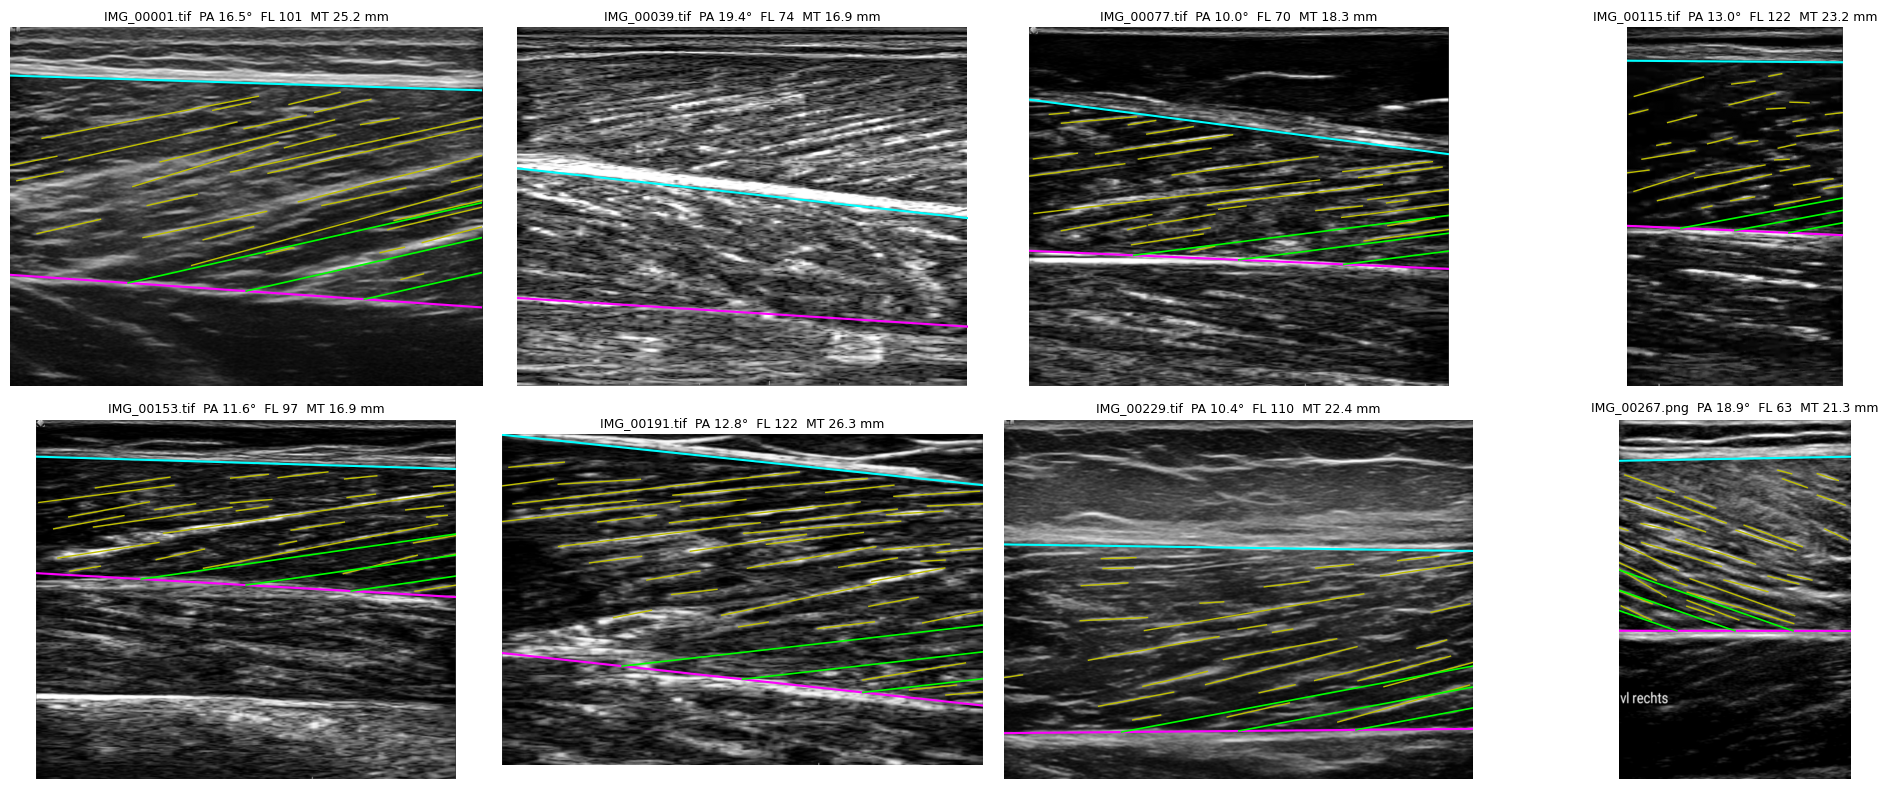

In [13]:
def draw_qc(i, ax):
    r = RESULTS[i]
    c = crop(read_gray(r["path"]), r["box"])
    H, W = c.shape
    ax.imshow(c, cmap="gray"); ax.set_xlim(0, W); ax.set_ylim(H, 0)
    if r["apo"] is not None:
        xx = np.array([0, W])
        for key, col in (("sup", "cyan"), ("deep", "magenta")):
            a, b = r["apo"][key]; ax.plot(xx, a * xx + b, col, lw=1.5)
    for s in r["segs"]:
        L = s["length"] / 2
        ax.plot([s["cx"] - L * s["dx"], s["cx"] + L * s["dx"]], [s["cy"] - L * s["dy"], s["cy"] + L * s["dy"]], "y-", lw=1)
    for q, e in r["fl_lines"]:
        ax.plot([q[0], e[0]], [q[1], e[1]], "lime", lw=1.2)
    row = sub.set_index("image_id").loc[i]
    ax.set_title(f"{i}  PA {row.pa_deg:.1f}°  FL {row.fl_mm:.0f}  MT {row.mt_mm:.1f} mm", fontsize=9)
    ax.axis("off")

show = list(RESULTS)[:: max(1, len(RESULTS) // 8)][:8]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax in axes.ravel():
    ax.axis("off")
for i, ax in zip(show, axes.ravel()):
    draw_qc(i, ax)
plt.tight_layout(); plt.savefig(WORK / "qc_examples.png", dpi=80); plt.show()